# Missing fault analysis

**The fault-length distribution is a broken
power law with the break at the seismogenic thickness $T$ = 15 km**, and this single distribution is used for both the
missing-fault counts and the theoretical potency fraction $R(L)/R(L_{ref})$:

* $L < T$: $\alpha_s$ = 2.06, fixed ([Zou & Fialko (2024)](https://doi.org/10.1029/2024EA003824): their Fig. 6 envelope of the fault-trace and outcrop data; b ≈ 1 of
  earthquakes with $L < T$, $\alpha_s = 2b$).
* $L \ge T$: $\alpha_l$ = exponent fitted to the merged traces (section 4, fit range above $T$).

Why $T$ and not $l_{min}$: $T$ is where the fault width saturates, which changes the moment–length scaling and, for b ≈ 1,
the expected exponent (Z&F 2024, sec. 4). $l_{min}$ only marks where the NSHM catalog stops being complete. Between $T$
and $l_{min}$ the exponent is not constrained by the data; the fitted $\alpha_l$ is extrapolated there.

Section 11b compares this model with the three variants (single fitted α; counts fitted + $R$ with 2.06; single
α = 2.06).

**Method in one table**

| Input data | Choice |
|---|---|
| Fault population | NSHM traces merged following the approach of Zou & Fialko 2024 (5 km, ≤ 30°); each fault's moment assigned to its merged trace |
| On-fault moment | slip-deficit model, **only patches inside the California strain polygon** (same area as the off-fault budget) |
| Off-fault budget | `Mo_sum_regions` only in regions shown in Fig. 2b (best fit, lower and upper bound models) |
| Power-law fit | **all merged traces**, San Andreas included: KS range selection + truncated MLE + bootstrap → α, $l_{min}$, $N_{tail}$ |
| Missing faults | theoretical count from the **broken power law** (α_s = 2.06 below $T$, fitted α above) − merged count, 10 km bins, anchored at $l_{min}$ |
| Theory curve | **conditional normalization**: $\big(M_{on}(\le L_{ref}) + M_{off}\big)\,R(L)/R(L_{ref})$ with the **same broken power law**, $L_{ref}$ = longest trace outside the San Andreas system |
| Allocation | off-fault budget added only to bins ≤ 100 km that have missing faults, rescaled to the budget |
| Outputs | slip deficit rate and earthquake rate of the missing faults per 10 km bin, with lower/upper bounds |

**Why the San Andreas is in the fit but out of the normalization** (section 5; Zou & Fialko 2024, *Earth Space Sci.*). The two San Andreas traces (> 550 km) are statistically expected by the fitted power law, so they
stay in the length statistics. Their moment rate is not: they carry about a third of the on-fault moment, about twice
what $R(L)$ gives faults of that length. Z&F treat mature plate-boundary faults as a separate regime (their Fig. 9),
and they suggest that the "missing slip" might be associated with regions of diffuse deformation. The normalization therefore uses the
population up to $L_{ref}$.

**Pipeline**

1. Configuration
2. On-fault model: fault lengths and per-fault moment rates. 1b. Restriction to the California polygon.
3. Off-fault moment budgets.
4. Merging of fault traces; modeled cumulative moment $M_{on}(L)$ by merged length.
5. Power-law fit of the merged lengths.
6. San Andreas as a separate mature population: diagnostics and $L_{ref}$.
7. Conditional theoretical potency fraction $R(L)/R(L_{ref})$.
8. Missing faults per 10 km bin.
9. Per-bin addition of the off-fault budget (conditional target curve).
10. Slip deficit rates and earthquake rates (+ Gutenberg–Richter comparison).
11. Four-panel figure.
12. Summary table and CSV. 11b. Comparison with the earlier single-exponent variants.
13. Notes and caveats.

## 0. Configuration

In [1]:
import os
from collections import defaultdict
from pathlib import Path

import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.gridspec as gridspec

import sys
sys.path.insert(0, "../Input_data/modules")   # local Python modules (run from Natgeo_supplements/Notebooks)
from fault_length_pipeline import run_pipeline, fialko_cum_frac
from fault_merge import merge_fault_traces_matlab_equiv

# --- Input files ---
_FAULT_STATS_CANDIDATES = [Path("../Input_data/datasets/fault_statistics")]
FAULT_STATS_DIR = next((d for d in _FAULT_STATS_CANDIDATES if (d / "inputs_CALI_natgeo_faults.mat").exists()), None)
if FAULT_STATS_DIR is None:
    raise FileNotFoundError(f"inputs_CALI_natgeo_faults.mat not found in {[str(d) for d in _FAULT_STATS_CANDIDATES]}")
MAT_BEST  = FAULT_STATS_DIR / "inputs_CALI_natgeo_faults.mat"   # best-fit model
MAT_LOWER = FAULT_STATS_DIR / "input_lower_bound.mat"           # minimizes off-fault deformation
MAT_UPPER = FAULT_STATS_DIR / "input_upper_bound.mat"           # maximizes off-fault deformation
for p in (MAT_BEST, MAT_LOWER, MAT_UPPER):
    if not p.exists():
        raise FileNotFoundError(f"{p} -> {os.path.realpath(p)} not found (broken symlink?)")
    if not h5py.is_hdf5(p):
        raise ValueError(f"{p} is not a MATLAB v7.3 (HDF5) file")
    print(f"{p.name:32s} -> {os.path.realpath(p)}  ({p.stat().st_size / 1e9:.2f} GB)")

OUTPUT_DIR = Path("../output_data/Section_10_combined_test")
FIG_OUT = OUTPUT_DIR / "figures"
FIG_OUT.mkdir(parents=True, exist_ok=True)
OUT_PREFIX = str(OUTPUT_DIR / "CAL_results_test")

# --- California polygon (lon,lat pairs, comma separated) and origin of the model's local XY coordinates ---
POLY_FILE = Path("../Input_data/datasets/ancillary_map_files/California_strain_poly.gmt")
LOCAL_ORIGIN_LONLAT = (-114.0, 40.0)    # MATLAB: origin = [40 -114] (lat, lon); local2llh(xy, fliplr(origin))

# --- Binning ---
HIST_EDGES_KM = np.arange(0, 250, 10)    # bins passed to run_pipeline (original-length curve, for comparison only)
BIN_KM = 10.0                            # width of the merged-length moment bins
PANEL_EDGES_KM = np.arange(0, 110, 10)   # 10 km bins used in panels b-d (0-100 km)

# --- Physical / model parameters ---
MERGE_EPS_KM = 5.0          # max endpoint gap for merging traces
T_KM = 15.0                 # seismogenic thickness: transition length in R(L) and fault width W
# L_max of the theory is NOT set here: it is the upper end of the power-law fitting range (section 4)
L_CUT_KM = 100.0            # outer limit: off-fault moment is only added to bins with L <= L_CUT_KM ...
                            # ... and, within that, only to bins with missing faults (section 6)
L_COUNT_FLOOR_KM = 5.0      # lower length used for the first (0-10 km) count bin, avoids N(>=0) = inf

# --- Broken power law: exponent below the break (above the break: fitted in section 4) ---
ALPHA_SHORT = 2.06          # L < L_BREAK_KM; Zou & Fialko (2024), Fig. 6 envelope, consistent with b = 1 (alpha = 2b)
L_BREAK_KM = T_KM           # break at the seismogenic thickness (width saturation), NOT at lmin

# --- Power-law fit settings (Clauset-style two-sided range selection) ---
KS_TOL = 0.1
MIN_IN_RANGE = 10
MIN_WIDTH_DECADES = 0.75
N_BOOT = 2000
RNG_SEED = 12345

# --- Magnitude scaling ---
def mw_from_length(L_km):
    """Wells & Coppersmith (1994), all slip types: log10(SRL) = -3.55 + 0.74 Mw."""
    return (np.log10(L_km) + 3.55) / 0.74

def m0_from_mw(mw):
    """Hanks & Kanamori (1979), N·m."""
    return 10 ** (1.5 * mw + 9.1)

def load_h5_scalar(path, key):
    """Read one scalar variable from an HDF5 (v7.3) .mat file without loading the whole file."""
    with h5py.File(path, "r") as f:
        return float(np.asarray(f[key]).squeeze())

inputs_CALI_natgeo_faults.mat    -> /Users/jcastrop/Documents/PhD_IU/California_paper_materials/Natgeo_supplements/Input_data/datasets/fault_statistics/inputs_CALI_natgeo_faults.mat  (1.46 GB)
input_lower_bound.mat            -> /Users/jcastrop/Documents/PhD_IU/California_paper_materials/Natgeo_supplements/Input_data/datasets/fault_statistics/input_lower_bound.mat  (1.46 GB)
input_upper_bound.mat            -> /Users/jcastrop/Documents/PhD_IU/California_paper_materials/Natgeo_supplements/Input_data/datasets/fault_statistics/input_upper_bound.mat  (1.46 GB)


## 1. On-fault model: fault lengths and cumulative moment rate

`run_pipeline` computes, for each original fault (`seg_id`), its length (sum of top-patch lengths) and its moment rate
$\mu\sum A\,b_s$ over top and deep patches. Its cumulative curve by **original** length is kept only for comparison
(`Mo_on_cum_orig`); the curve used in the analysis is rebuilt from merged traces in section 3.

In [2]:
res = run_pipeline(str(MAT_BEST), HIST_EDGES_KM, length_col=0, compute_strain=False)

FaultLengths_orig = res["FaultLengths"]               # bin upper edges (km), original lengths
Mo_on_cum_orig = np.asarray(res["Mo_on"], float)      # cumulative on-fault moment by ORIGINAL length (comparison only)
Mo_per_seg = res["Mo_per_seg"]              # {fault_id: moment rate}
fault_traces = res["fault_traces"]
Lseg_km = res["Lseg_km"]
mu = load_h5_scalar(MAT_BEST, "mu")

Mtot_on = Mo_on_cum_orig[-1]

print(f"Original faults: {len(Lseg_km)}   longest: {Lseg_km.max():.1f} km")
print(f"Total on-fault moment rate: {Mtot_on:.3e} N·m/yr   (mu = {mu:.2e} Pa)")
assert Lseg_km.max() <= FaultLengths_orig[-1], "Some faults are longer than the last histogram edge"

dict_keys(['#refs#', 'A_bot', 'A_top', 'FaultLengths_km', 'GExx', 'GExx_perp', 'GExx_top', 'GExx_top_perp', 'GExy', 'GExy_perp', 'GExy_top', 'GExy_top_perp', 'GEyy', 'GEyy_perp', 'GEyy_top', 'GEyy_top_perp', 'Lseg_km', 'Mo_off', 'Mo_sum_regions', 'bs_bot', 'bs_bot_perp', 'bs_bot_rake', 'bs_top', 'bs_top_perp', 'bs_top_rake', 'hist_edges_km', 'meta', 'mu', 'pm_seg_id', 'pm_top', 'pm_top_seg_id', 'seg_ids', 'segends', 'segends_id'])
Original faults: 395   longest: 235.7 km
Total on-fault moment rate: 1.814e+19 N·m/yr   (mu = 3.00e+10 Pa)


## 1b. On-fault moment inside the California polygon

**Method**

1. Patch moment rate: $\mu A b_s$ for every top patch (`A_top`, `bs_top`) and every bottom patch (`A_bot`, `bs_bot`).
2. Patch centroids: `pm_top` columns 6–7 are local east/north (km) with origin 40°N, 114°W. They are converted to
   lon/lat with a Python port of `local2llh.m` (inverse polyconic, WGS84).
3. `inpolygon` test against `California_strain_poly.gmt`.

**Bottom patches.** The `.mat` file stores centroids only for the top patches (`pm_top`). Every top patch has exactly
two bottom patches below it: same fault id, same area, consecutive in the down-dip order of `patchfault`. This is
checked below. Each bottom patch takes the inside/outside flag of its top patch. On a dipping fault the bottom patches
sit a few km down-dip of the top patch, so near the polygon edge the flag could differ. The cell bounds this by moving
each bottom patch down-dip in both possible dip directions and reporting the moment whose flag would change.

**Result.** `Mo_per_seg`, `Mo_on_cum_orig` and `Mtot_on` are **rebound** to the polygon values. Everything after this
cell uses them unchanged.

On-fault moment rate (best-fit slip-deficit model)
  whole model domain (used in merged_reproducible_research.ipynb): 1.8137e+19 N·m/yr
  inside the California polygon (used from here on)              : 1.7328e+19 N·m/yr (95.5% of the domain total)
  removed (patches outside the polygon)                          : 8.0891e+17 N·m/yr
Patches inside: top 1768/1898, bottom 3536/3796
Original faults: 337 entirely inside, 20 crossing the edge, 38 entirely outside
Bottom-patch approximation: moment whose flag could change if bottom patches are shifted down-dip: 5.85e+16 N·m/yr (0.34% of the polygon total)
Off-fault budget inside the same polygon (Mo_sum_regions, best): 9.0040e+18 N·m/yr


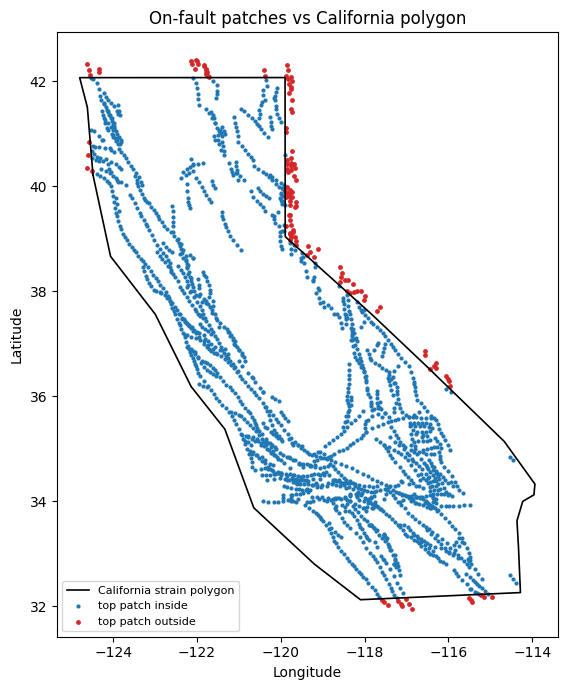

In [3]:
from matplotlib.path import Path as MplPath


def local2llh(x_km, y_km, origin_lonlat):
    """Port of local2llh.m (Cervelli 2000): iterative inverse polyconic projection, WGS84. x, y in km -> lon, lat (deg)."""
    a, e = 6378137.0, 0.08209443794970
    x = np.asarray(x_km, float) * 1000.0
    y = np.asarray(y_km, float) * 1000.0
    lon0, lat0 = np.radians(origin_lonlat[0]), np.radians(origin_lonlat[1])
    c1 = 1 - e**2 / 4 - 3 * e**4 / 64 - 5 * e**6 / 256
    c2 = 3 * e**2 / 8 + 3 * e**4 / 32 + 45 * e**6 / 1024
    c3 = 15 * e**4 / 256 + 45 * e**6 / 1024
    c4 = 35 * e**6 / 3072
    arc = lambda p: a * (c1 * p - c2 * np.sin(2 * p) + c3 * np.sin(4 * p) - c4 * np.sin(6 * p))
    A = (arc(lat0) + y) / a
    B = x**2 / a**2 + A**2
    lat = A.copy()
    for _ in range(100):
        C = np.sqrt(1 - e**2 * np.sin(lat)**2) * np.tan(lat)
        Ma = arc(lat) / a
        Mn = c1 + 2 * c2 * np.cos(2 * lat) + 4 * c3 * np.cos(4 * lat) - 6 * c4 * np.cos(6 * lat)  # as written in local2llh.m
        delta = -(A * (C * Ma + 1) - Ma - 0.5 * (Ma**2 + B) * C) / (
            e**2 * np.sin(2 * lat) * (Ma**2 + B - 2 * A * Ma) / (4 * C) + (A - Ma) * (C * Mn - 2 / np.sin(2 * lat)) - Mn)
        lat = lat + delta
        if np.max(np.abs(delta)) <= 1e-8:
            break
    else:
        raise RuntimeError("local2llh: convergence failure")
    lon = np.arcsin(x * C / a) / np.sin(lat) + lon0
    return np.degrees(lon), np.degrees(lat)


# --- Polygon ---
poly_lonlat = np.loadtxt(POLY_FILE, delimiter=",")
ca_poly = MplPath(poly_lonlat)

# --- Patch geometry and moment (read directly from the .mat file) ---
with h5py.File(MAT_BEST, "r") as f:
    pm_top = np.asarray(f["pm_top"]).T                          # [N_top, 7]: L, W, depth, dip, strike, east, north
    top_sid = np.asarray(f["pm_top_seg_id"]).ravel().astype(int)
    bot_sid = np.asarray(f["pm_seg_id"]).ravel().astype(int)
    A_top, A_bot = np.asarray(f["A_top"]).ravel(), np.asarray(f["A_bot"]).ravel()
    bs_top, bs_bot = np.asarray(f["bs_top"]).ravel(), np.asarray(f["bs_bot"]).ravel()
Mo_top_patch = mu * A_top * bs_top
Mo_bot_patch = mu * A_bot * bs_bot

# Bottom patch -> parent top patch: two bottom patches per top patch, in order, within each fault id
parent = np.empty(len(bot_sid), int)
for sid in np.unique(top_sid):
    it, ib = np.flatnonzero(top_sid == sid), np.flatnonzero(bot_sid == sid)
    assert len(ib) == 2 * len(it), f"fault {sid}: {len(ib)} bottom vs {len(it)} top patches"
    parent[ib] = np.repeat(it, 2)
assert np.allclose(A_bot, A_top[parent]), "bottom/top pairing check failed (areas differ)"

# Inside test (top patch centroids; bottom patches inherit the flag of their top patch)
lon_top, lat_top = local2llh(pm_top[:, 5], pm_top[:, 6], LOCAL_ORIGIN_LONLAT)
in_top = ca_poly.contains_points(np.column_stack([lon_top, lat_top]))
in_bot = in_top[parent]

# Bound on the bottom-patch approximation: shift each bottom patch down-dip by (row) * W * cos(dip), both directions
row = np.tile([1, 2], len(parent) // 2)          # 1st / 2nd bottom patch below the top patch
W, dip, strike = pm_top[parent, 1], np.radians(pm_top[parent, 3]), np.radians(pm_top[parent, 4])
dh = row * W * np.cos(dip)
flip = np.zeros(len(parent), bool)
for sgn in (+1, -1):
    az = strike + sgn * np.pi / 2
    lo_, la_ = local2llh(pm_top[parent, 5] + dh * np.sin(az), pm_top[parent, 6] + dh * np.cos(az), LOCAL_ORIGIN_LONLAT)
    flip |= ca_poly.contains_points(np.column_stack([lo_, la_])) != in_bot
Mo_bot_ambiguous = Mo_bot_patch[flip].sum()

# --- Per-fault moment: full (check against run_pipeline) and inside the polygon ---
Mo_per_seg_full = dict(Mo_per_seg)
Mo_per_seg_poly = {}
for sid in np.unique(top_sid):
    chk_full = Mo_top_patch[top_sid == sid].sum() + Mo_bot_patch[bot_sid == sid].sum()
    assert np.isclose(chk_full, Mo_per_seg_full[int(sid)], rtol=1e-10), f"fault {sid}: moment mismatch"
    Mo_per_seg_poly[int(sid)] = (Mo_top_patch[(top_sid == sid) & in_top].sum()
                                 + Mo_bot_patch[(bot_sid == sid) & in_bot].sum())

Mtot_on_full = Mtot_on
Mtot_on_poly = sum(Mo_per_seg_poly.values())
assert np.isclose(Mtot_on_full, Mo_top_patch.sum() + Mo_bot_patch.sum())

# Cumulative curve by ORIGINAL length (comparison only), rebuilt from the per-fault polygon moments
seg_ids_orig = np.asarray(res["seg_ids"]).astype(int)
def cum_by_orig_length(mo_dict):
    mo = np.array([mo_dict.get(int(s), 0.0) for s in seg_ids_orig])
    return np.array([mo[Lseg_km <= Lb].sum() for Lb in FaultLengths_orig])
assert np.allclose(cum_by_orig_length(Mo_per_seg_full), Mo_on_cum_orig, rtol=1e-10)

# --- Rebind: everything below uses the polygon moments ---
Mo_per_seg = Mo_per_seg_poly
Mo_on_cum_orig = cum_by_orig_length(Mo_per_seg_poly)
Mtot_on = Mtot_on_poly

# --- Report ---
frac_in = np.array([Mo_per_seg_poly[s] / Mo_per_seg_full[s] if Mo_per_seg_full[s] > 0 else np.nan
                    for s in Mo_per_seg_full])
n_in_top = {s: np.mean(in_top[top_sid == s]) for s in np.unique(top_sid)}
n_all_in = sum(v == 1 for v in n_in_top.values())
n_all_out = sum(v == 0 for v in n_in_top.values())
print("On-fault moment rate (best-fit slip-deficit model)")
print(f"  whole model domain (used in merged_reproducible_research.ipynb): {Mtot_on_full:.4e} N·m/yr")
print(f"  inside the California polygon (used from here on)              : {Mtot_on_poly:.4e} N·m/yr "
      f"({Mtot_on_poly / Mtot_on_full:.1%} of the domain total)")
print(f"  removed (patches outside the polygon)                          : {Mtot_on_full - Mtot_on_poly:.4e} N·m/yr")
print(f"Patches inside: top {in_top.sum()}/{len(in_top)}, bottom {in_bot.sum()}/{len(in_bot)}")
print(f"Original faults: {n_all_in} entirely inside, {len(n_in_top) - n_all_in - n_all_out} crossing the edge, "
      f"{n_all_out} entirely outside")
print(f"Bottom-patch approximation: moment whose flag could change if bottom patches are shifted down-dip: "
      f"{Mo_bot_ambiguous:.2e} N·m/yr ({Mo_bot_ambiguous / Mtot_on_poly:.2%} of the polygon total)")
print(f"Off-fault budget inside the same polygon (Mo_sum_regions, best): {load_h5_scalar(MAT_BEST, 'Mo_sum_regions'):.4e} N·m/yr")

# Map: patches inside / outside, and fraction of each fault's moment inside
fig, ax = plt.subplots(figsize=(6.5, 7))
ax.plot(*poly_lonlat.T, "k-", lw=1.2, label="California strain polygon")
ax.scatter(lon_top[in_top], lat_top[in_top], s=4, c="tab:blue", label="top patch inside")
ax.scatter(lon_top[~in_top], lat_top[~in_top], s=6, c="tab:red", label="top patch outside")
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude"); ax.set_aspect(1 / np.cos(np.radians(37)))
ax.legend(loc="lower left", fontsize=8); ax.set_title("On-fault patches vs California polygon")
plt.tight_layout(); plt.savefig(FIG_OUT / "onfault_patches_polygon.png", dpi=300, bbox_inches="tight"); plt.show()

## 2. Off-fault moment budget (best fit and bounds)

`Mo_sum_regions` is the off-fault moment rate inside the study polygons, after accounting for elastic heterogeneity and
viscoelastic earthquake-cycle effects. This is the budget distributed among fault-length bins below.

In [ ]:
# --- Off-fault budgets ---
# Note that these off-fault budgets are very conservative: 
# They only include off-fault moment rates inside the 4 regions shown in Fig. 2b of our manuscript
# They do not include off-fault moment rate from South of the Salton Sea, or from the Mendocino region,
# Which show significant off-fault moment rates. So the results derived in this notenook should be considered 
# as a lower bound on the missing number of faults and off-fault moment accomodated by them.
budgets = {
    "best":  load_h5_scalar(MAT_BEST,  "Mo_sum_regions"),
    "lower": load_h5_scalar(MAT_LOWER, "Mo_sum_regions"),
    "upper": load_h5_scalar(MAT_UPPER, "Mo_sum_regions"),
}
for k, v in budgets.items():
    print(f"Mo_sum_regions ({k:5s}): {v:.3e} N·m/yr   off-fault share of total: {100 * v / (Mtot_on + v):.1f} %")

Mo_sum_regions (best ): 9.004e+18 N·m/yr   off-fault share of total: 34.2 %
Mo_sum_regions (lower): 7.626e+18 N·m/yr   off-fault share of total: 30.6 %
Mo_sum_regions (upper): 1.007e+19 N·m/yr   off-fault share of total: 36.8 %


## 3. Merging fault traces

NSHM faults are split into sections, which biases the length distribution toward short faults. Traces are joined
(`Input_data/modules/fault_merge.py`) when their endpoints are closer than
5 km and their strikes are compatible (≤ 30°), or when they touch (≤ 0.1 km).

Each original `fault_id` is assigned to the longest merged trace that contains it, so moment is conserved.

The modeled cumulative moment curve $M_{on}(L)$ is then rebuilt by binning each merged trace's moment by its
**merged** length (10 km bins up to the longest merged trace). Total moment is preserved.

In [5]:
merged = merge_fault_traces_matlab_equiv(fault_traces, eps=MERGE_EPS_KM)

def trace_length(tr):
    return float(np.sum(np.hypot(np.diff(tr["xs"]), np.diff(tr["ys"]))))

merged_lengths = np.array([trace_length(t) for t in merged])

# Moment bookkeeping: each fault_id belongs to the longest merged trace containing it
fid_owner = {}
for idx, tr in enumerate(merged):
    for fid in tr["contributing_fault_ids"]:
        if fid not in fid_owner or merged_lengths[idx] > merged_lengths[fid_owner[fid]]:
            fid_owner[fid] = idx
merged_moments = np.zeros(len(merged))
for fid, idx in fid_owner.items():
    merged_moments[idx] += Mo_per_seg.get(fid, 0.0)

unclaimed = set(Mo_per_seg) - set(fid_owner)
print(f"Traces: {len(fault_traces)} original -> {len(merged)} merged   longest merged: {merged_lengths.max():.1f} km")
print(f"Moment conservation: original {sum(Mo_per_seg.values()):.6e}, merged {merged_moments.sum():.6e}")
print(f"Unclaimed fault ids: {len(unclaimed)}")
# Polygon restriction (section 1b): traces outside the polygon keep their length but carry no moment
merged_moments_full = np.zeros(len(merged))
for fid, idx in fid_owner.items():
    merged_moments_full[idx] += Mo_per_seg_full.get(fid, 0.0)
share_in = np.divide(merged_moments, merged_moments_full, out=np.full(len(merged), np.nan), where=merged_moments_full > 0)
print(f"Merged traces: {np.sum(share_in == 1)} fully inside the polygon, {np.sum((share_in > 0) & (share_in < 1))} partly, "
      f"{np.sum(share_in == 0)} entirely outside (zero moment, but they stay in the length statistics)")

# Cumulative on-fault moment curve by MERGED length (used in everything below)
MERGED_EDGES_KM = np.arange(0.0, np.ceil(merged_lengths.max() / BIN_KM) * BIN_KM + BIN_KM / 2, BIN_KM)
FaultLengths = MERGED_EDGES_KM[1:]                                   # bin upper edges 10..560 km
perbin_model_on, _ = np.histogram(merged_lengths, bins=MERGED_EDGES_KM, weights=merged_moments)
Mo_on_cum = np.cumsum(perbin_model_on)
assert np.isclose(Mo_on_cum[-1], Mtot_on), "Merged moment curve does not conserve total on-fault moment"
print(f"Merged moment curve: {len(FaultLengths)} bins up to {FaultLengths[-1]:.0f} km, total {Mo_on_cum[-1]:.3e} N·m/yr")

Traces: 405 original -> 307 merged   longest merged: 554.6 km
Moment conservation: original 1.732778e+19, merged 1.732778e+19
Unclaimed fault ids: 0
Merged traces: 134 fully inside the polygon, 76 partly, 36 entirely outside (zero moment, but they stay in the length statistics)
Merged moment curve: 56 bins up to 560 km, total 1.733e+19 N·m/yr


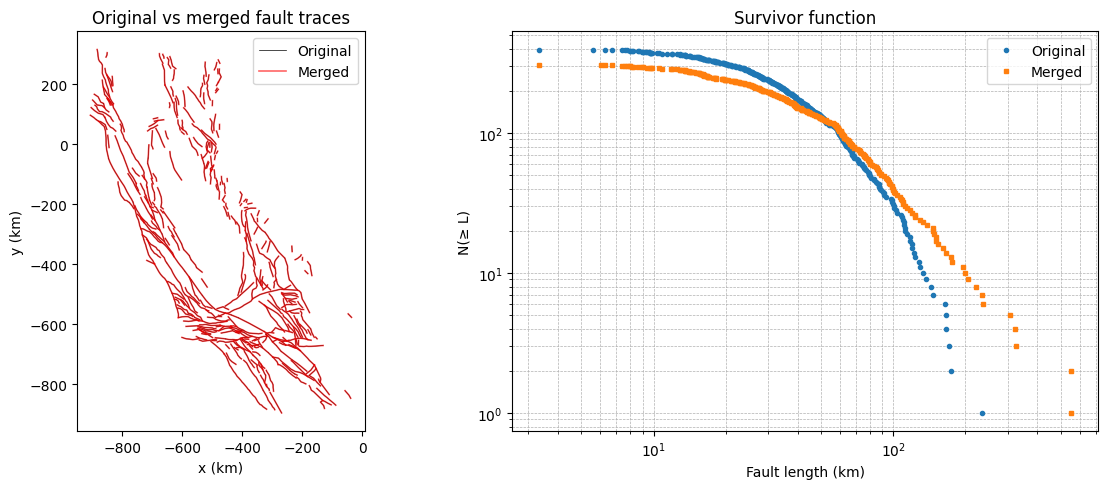

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
for i, tr in enumerate(fault_traces):
    ax1.plot(tr["xs"], tr["ys"], color="k", lw=0.5, label="Original" if i == 0 else None)
for i, tr in enumerate(merged):
    ax1.plot(tr["xs"], tr["ys"], color="red", lw=1.2, alpha=0.6, label="Merged" if i == 0 else None)
ax1.set_aspect("equal"); ax1.set_xlabel("x (km)"); ax1.set_ylabel("y (km)"); ax1.legend()
ax1.set_title("Original vs merged fault traces")

for L, lab, mk in [(Lseg_km, "Original", "o"), (merged_lengths, "Merged", "s")]:
    Ls = np.sort(L)
    ax2.loglog(Ls, len(Ls) - np.arange(len(Ls)), mk, ms=3, label=lab)
ax2.set_xlabel("Fault length (km)"); ax2.set_ylabel("N(≥ L)")
ax2.grid(True, which="both", ls="--", lw=0.5); ax2.legend()
ax2.set_title("Survivor function")
plt.tight_layout(); plt.savefig(FIG_OUT / "merged_fault_traces_survivor.png", dpi=300, bbox_inches="tight"); plt.show()

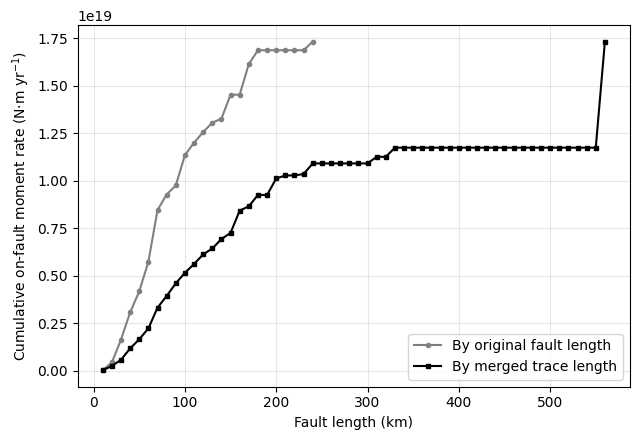

Share of on-fault moment on faults <=  10 km:  original   0.2%   merged   0.1%
Share of on-fault moment on faults <=  20 km:  original   2.5%   merged   1.5%
Share of on-fault moment on faults <=  50 km:  original  24.1%   merged   9.6%
Share of on-fault moment on faults <= 100 km:  original  65.5%   merged  29.8%


In [7]:
# Where does merging move moment? Cumulative on-fault moment by original vs merged length
plt.figure(figsize=(6.5, 4.5))
plt.plot(FaultLengths_orig, Mo_on_cum_orig, "o-", ms=3, color="gray", label="By original fault length")
plt.plot(FaultLengths, Mo_on_cum, "s-", ms=3, color="k", label="By merged trace length")
plt.xlabel("Fault length (km)"); plt.ylabel(r"Cumulative on-fault moment rate (N$\cdot$m yr$^{-1}$)")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.savefig(FIG_OUT / "cell12_length_distribution.png", dpi=300, bbox_inches="tight"); plt.show()
for L in (10, 20, 50, 100):
    print(f"Share of on-fault moment on faults <= {L:3d} km:  original {Mo_on_cum_orig[FaultLengths_orig == L][0] / Mtot_on:6.1%}"
          f"   merged {Mo_on_cum[FaultLengths == L][0] / Mtot_on:6.1%}")

## 4. Power-law fit of the merged fault lengths

For a differential distribution $n(L)\propto L^{-\beta}$ above $l_{min}$, the MLE is
$\hat\beta = 1 + n / \sum_i \ln(L_i/l_{min})$ and the cumulative exponent is $\alpha = \hat\beta - 1$
($N(\ge L)\propto L^{-\alpha}$).

The range $[l_{min}, l_{max}]$ is chosen by scanning all candidate pairs: a truncated power-law CDF must match the
empirical CDF with KS ≤ 0.1, contain ≥ 10 faults and span ≥ 0.75 decades. Among admissible ranges the one with the most
faults wins (ties → smaller $l_{min}$).

In this notebook the fitted $\alpha$ is the **long-fault exponent** $\alpha_l$ ($L \ge T$). The fit range lies entirely
above $T$, so it says nothing about $L < T$, where $\alpha_s$ = 2.06 is used (sections 6–7).

The CCDF linear regression is computed **only as a consistency check** of $\alpha$; it is not used downstream.

In [8]:
def mle_beta(data, lmin, lmax=np.inf):
    tail = data[(data >= lmin) & (data <= lmax)]
    if len(tail) < 2:
        return np.nan
    return 1.0 + len(tail) / np.sum(np.log(tail / lmin))

def truncated_cdf(x, lmin, lmax, beta):
    if abs(beta - 1.0) < 1e-12:
        return np.log(x / lmin) / np.log(lmax / lmin)
    return (1.0 - (x / lmin) ** (1.0 - beta)) / (1.0 - (lmax / lmin) ** (1.0 - beta))

L_all = merged_lengths[np.isfinite(merged_lengths) & (merged_lengths > 0)]
L_sorted = np.sort(L_all)
lmin_cands = np.unique(L_sorted[: max(1, int(0.8 * len(L_sorted)))])

candidates = []
for lmin_c in lmin_cands:
    beta_c = mle_beta(L_all, lmin_c)
    if not np.isfinite(beta_c):
        continue
    best = None
    for lmax_c in np.unique(L_sorted[L_sorted >= lmin_c]):
        if np.log10(lmax_c / lmin_c) < MIN_WIDTH_DECADES:
            continue
        x = L_sorted[(L_sorted >= lmin_c) & (L_sorted <= lmax_c)]
        if len(x) < MIN_IN_RANGE:
            continue
        ks = np.max(np.abs(np.arange(1, len(x) + 1) / len(x) - truncated_cdf(x, lmin_c, lmax_c, beta_c)))
        if ks <= KS_TOL and (best is None or len(x) > best[1] or (len(x) == best[1] and ks < best[2])):
            best = (float(lmax_c), len(x), float(ks))
    if best is not None:
        candidates.append({"lmin": float(lmin_c), "lmax": best[0], "n": best[1], "ks": best[2]})

if not candidates:
    raise RuntimeError("No [lmin, lmax] range satisfies the KS criteria.")
chosen = sorted(candidates, key=lambda r: (-r["n"], r["lmin"], r["ks"]))[0]
LMIN, LMAX_FIT = chosen["lmin"], chosen["lmax"]

L_fit = L_all[(L_all >= LMIN) & (L_all <= LMAX_FIT)]
BETA = mle_beta(L_all, LMIN, LMAX_FIT)
ALPHA = BETA - 1.0                        # <-- long-fault exponent alpha_l (L >= T); alpha_s = ALPHA_SHORT below T
N_TAIL = int(np.sum(L_all >= LMIN))       # anchor of the fault-count curve

# Bootstrap CI
rng = np.random.default_rng(RNG_SEED)
boot_beta = np.array([mle_beta(rng.choice(L_fit, len(L_fit), replace=True), LMIN, LMAX_FIT) for _ in range(N_BOOT)])
boot_beta = boot_beta[np.isfinite(boot_beta)]
ALPHA_CI = np.percentile(boot_beta, [2.5, 97.5]) - 1.0

# CCDF regression (consistency check only)
ux = np.unique(L_sorted)
uy = np.array([np.sum(L_sorted >= x) for x in ux])
m = (ux >= LMIN) & (ux <= LMAX_FIT)
ccdf_slope, ccdf_icpt = np.polyfit(np.log10(ux[m]), np.log10(uy[m]), 1)

print(f"Fitting range: lmin = {LMIN:.2f} km, lmax = {LMAX_FIT:.2f} km, n = {len(L_fit)} (KS = {chosen['ks']:.3f})")
print(f"MLE beta = {BETA:.3f}  ->  alpha = {ALPHA:.3f}   95% bootstrap CI: [{ALPHA_CI[0]:.3f}, {ALPHA_CI[1]:.3f}]")
print(f"Check: CCDF regression slope = {ccdf_slope:.3f} (-alpha = {-ALPHA:.3f})")
print(f"Merged faults with L >= lmin (count anchor): N_TAIL = {N_TAIL}")

LMAX_THEORY_KM = LMAX_FIT                 # L_max of R(L) = upper end of the range used to derive alpha
print(f"L_max used in R(L): {LMAX_THEORY_KM:.1f} km (longest merged trace: {merged_lengths.max():.1f} km)")

Fitting range: lmin = 51.54 km, lmax = 554.63 km, n = 124 (KS = 0.092)
MLE beta = 2.774  ->  alpha = 1.774   95% bootstrap CI: [1.543, 2.083]
Check: CCDF regression slope = -1.936 (-alpha = -1.774)
Merged faults with L >= lmin (count anchor): N_TAIL = 124
L_max used in R(L): 554.6 km (longest merged trace: 554.6 km)


Broken power law: alpha_s = 2.06 for L < 15 km, alpha_l = 1.774 above; N(>= T) = 1106.9, N(>= 5 km) = 9316 (single fitted alpha: 7769)


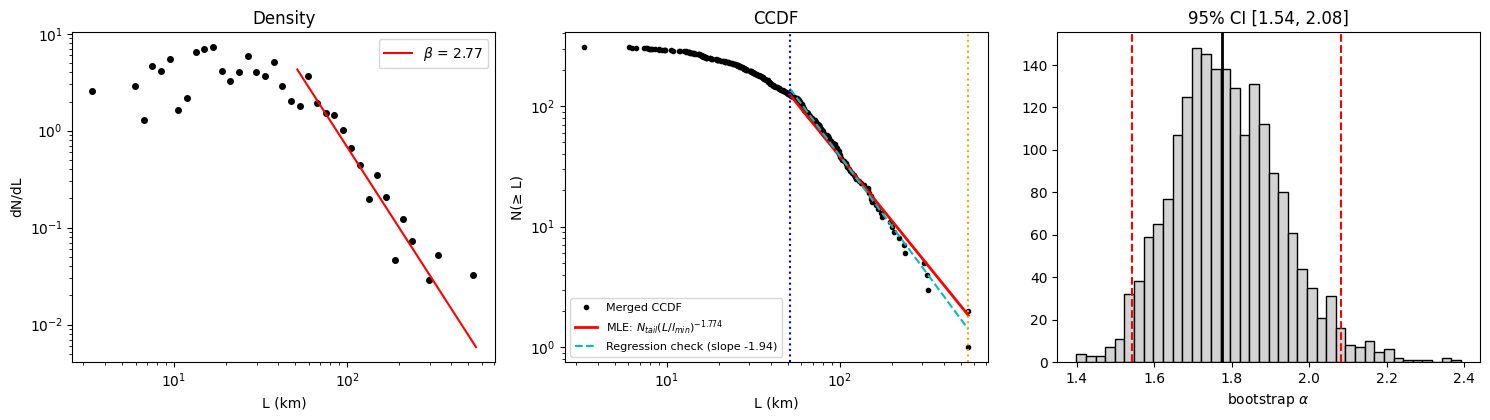

In [9]:
def n_ge_model(L_km, a_short, a_long, Lb=L_BREAK_KM):
    """N(>= L) of a broken power law: density n(L) ~ L^-(a+1), a = a_short below Lb and a_long above, continuous at Lb.
    Above Lb: N_TAIL (L/LMIN)^-a_long (the fit). Below Lb: N(Lb) [1 + (a_long/a_short)((L/Lb)^-a_short - 1)].
    With a_short == a_long this is the single power law N_TAIL (L/LMIN)^-a."""
    L = np.asarray(L_km, float)
    N_b = N_TAIL * (Lb / LMIN) ** (-a_long)
    above = N_TAIL * (L / LMIN) ** (-a_long)
    below = N_b * (1.0 + (a_long / a_short) * ((L / Lb) ** (-a_short) - 1.0))
    return np.where(L >= Lb, above, below)


def potency_cum(L_km, a_short, a_long, T=T_KM, Lb=L_BREAK_KM):
    """Cumulative potency of faults up to L (arbitrary units), Z&F (2024) Eqs. 6-7 with the broken density above.
    Width = L below T and T above; slip ~ L. Requires Lb == T (break at the width saturation)."""
    assert np.isclose(Lb, T), "the closed form assumes the break is at T"
    L = np.asarray(L_km, float)
    A1 = T ** (a_short - a_long)                      # density prefactor below T (continuity at T, prefactor 1 above)
    p_small = A1 * np.minimum(L, T) ** (3 - a_short) / (3 - a_short)
    Lg = np.maximum(L, T)
    if abs(a_long - 2) < 1e-9:
        p_large = T * np.log(Lg / T)
    else:
        p_large = T * (Lg ** (2 - a_long) - T ** (2 - a_long)) / (2 - a_long)
    return p_small + p_large


def n_ge(L_km):
    """Theoretical number of faults with length >= L: broken power law (ALPHA_SHORT below T, fitted ALPHA above)."""
    return n_ge_model(L_km, ALPHA_SHORT, ALPHA)


# Checks: single-exponent limits reproduce the earlier formulas
_Lc = np.array([3.0, 10.0, 15.0, 40.0, 200.0])
assert np.allclose(n_ge_model(_Lc, ALPHA, ALPHA), N_TAIL * (_Lc / LMIN) ** (-ALPHA))
assert np.allclose(potency_cum(_Lc, ALPHA, ALPHA) / potency_cum(LMAX_FIT, ALPHA, ALPHA),
                   fialko_cum_frac(_Lc, alpha=ALPHA, Lmax=LMAX_FIT, T=T_KM))
print(f"Broken power law: alpha_s = {ALPHA_SHORT:.2f} for L < {L_BREAK_KM:.0f} km, alpha_l = {ALPHA:.3f} above; "
      f"N(>= T) = {n_ge(L_BREAK_KM):.1f}, N(>= 5 km) = {n_ge(5.0):.0f} "
      f"(single fitted alpha: {n_ge_model(5.0, ALPHA, ALPHA):.0f})")

fig, axs = plt.subplots(1, 3, figsize=(15, 4.3))

# (i) dN/dL in log bins
logL = np.log10(L_all)
bins = np.arange(np.floor(logL.min()), np.ceil(logL.max()) + 0.05, 0.05)
cnt, be = np.histogram(logL, bins=bins)
dens = cnt / np.diff(10 ** be)
ok = dens > 0
xc = 10 ** (0.5 * (be[:-1] + be[1:]))
axs[0].loglog(xc[ok], dens[ok], "ko", ms=4)
Lline = np.logspace(np.log10(LMIN), np.log10(LMAX_FIT), 50)
axs[0].loglog(Lline, N_TAIL * ALPHA / LMIN * (Lline / LMIN) ** (-BETA), "r-", label=rf"$\beta$ = {BETA:.2f}")
axs[0].set_xlabel("L (km)"); axs[0].set_ylabel("dN/dL"); axs[0].legend(); axs[0].set_title("Density")

# (ii) CCDF with MLE line and regression check
axs[1].loglog(ux, uy, "ko", ms=3, label="Merged CCDF")
axs[1].loglog(Lline, n_ge(Lline), "r-", lw=2, label=rf"MLE: $N_{{tail}}(L/l_{{min}})^{{-{ALPHA:.3f}}}$")
axs[1].loglog(ux[m], 10 ** (ccdf_icpt + ccdf_slope * np.log10(ux[m])), "c--", label=f"Regression check (slope {ccdf_slope:.2f})")
for v, c in [(LMIN, "b"), (LMAX_FIT, "orange")]:
    axs[1].axvline(v, color=c, ls=":")
axs[1].set_xlabel("L (km)"); axs[1].set_ylabel("N(≥ L)"); axs[1].legend(fontsize=8); axs[1].set_title("CCDF")

# (iii) bootstrap
axs[2].hist(boot_beta - 1, bins=40, color="lightgray", edgecolor="k")
axs[2].axvline(ALPHA, color="k", lw=2)
for v in ALPHA_CI:
    axs[2].axvline(v, color="r", ls="--")
axs[2].set_xlabel(r"bootstrap $\alpha$"); axs[2].set_title(f"95% CI [{ALPHA_CI[0]:.2f}, {ALPHA_CI[1]:.2f}]")
plt.tight_layout(); plt.savefig(FIG_OUT / "length_density_ccdf_bootstrap.png", dpi=300, bbox_inches="tight"); plt.show()

## 5. The San Andreas as a separate, mature population

The two longest merged traces (> 550 km) are the San Andreas system. Two questions decide how to treat them:

* **Are they a count anomaly?** Compare the fault counts in the tail with the fit of section 4. If they match, the
  traces belong to the length statistics and stay in the fit.
* **Are they a moment anomaly?** Compare their share of the on-fault moment with the share $1 - R(L)$ the theory gives
  to faults of that length, and their equivalent slip rate with that of other long faults.

$L_{ref}$ is the longest trace outside the San Andreas system: the last length where the modeled curve is sampled
before the empty 325–553 km gap.

In [10]:
order = np.argsort(merged_lengths)[::-1]
SAF_IDX = order[:2]                                    # the two traces > 550 km (San Andreas system)
assert (merged_lengths[SAF_IDX] > 500).all(), "Expected the two longest merged traces to be longer than 500 km"
L_REF_KM = float(merged_lengths[order[len(SAF_IDX)]])  # longest trace outside the San Andreas system

# Equivalent slip rate = moment / (mu * L * W), W = min(L, T). For traces crossing the polygon edge this is diluted
# (full length, inside moment only).
W_eq_km = np.minimum(merged_lengths, T_KM)
eq_slip = merged_moments / (mu * merged_lengths * 1e3 * W_eq_km * 1e3) * 1e3        # mm/yr

top = pd.DataFrame({
    "trace": order[:6], "length_km": merged_lengths[order[:6]], "moment_Nm_yr": merged_moments[order[:6]],
    "share_of_on_fault": merged_moments[order[:6]] / Mtot_on, "equiv_slip_mm_yr": eq_slip[order[:6]],
    "n_original_faults": [len(merged[i]["contributing_fault_ids"]) for i in order[:6]],
})
print("Longest merged traces")
print(top.to_string(index=False, formatters={"length_km": "{:.1f}".format, "moment_Nm_yr": "{:.2e}".format,
                                              "share_of_on_fault": "{:.1%}".format, "equiv_slip_mm_yr": "{:.1f}".format}))

print("\nCount check: fault counts in the tail, fit of section 4 vs merged catalog")
for lo_, hi_ in [(100, 200), (200, 300), (300, 550), (550, np.inf)]:
    exp_ = n_ge(lo_) - (n_ge(hi_) if np.isfinite(hi_) else 0.0)
    obs_ = np.sum((merged_lengths >= lo_) & (merged_lengths < hi_))
    print(f"  {lo_:4.0f}-{hi_:<4} km: expected {exp_:5.2f}   observed {obs_}")

M_SAF = merged_moments[SAF_IDX].sum()
print(f"\nMoment check: San Andreas traces carry {M_SAF:.3e} N·m/yr = {M_SAF / Mtot_on:.1%} of the on-fault moment; "
      f"theory for L > {L_REF_KM:.0f} km: 1 - R(L_ref) = "
      f"{1 - potency_cum(L_REF_KM, ALPHA_SHORT, ALPHA) / potency_cum(LMAX_FIT, ALPHA_SHORT, ALPHA):.1%} (broken power law)")
print(f"Median equivalent slip rate of the other traces > 100 km: {np.median(eq_slip[(merged_lengths > 100) & (merged_lengths <= L_REF_KM)]):.1f} mm/yr")
print(f"\nL_ref = {L_REF_KM:.1f} km (longest trace outside the San Andreas system)")

Longest merged traces
 trace length_km moment_Nm_yr share_of_on_fault equiv_slip_mm_yr  n_original_faults
   300     554.6     2.96e+18             17.1%             11.9                  5
   304     553.2     2.63e+18             15.2%             10.6                  8
   302     325.2     2.89e+17              1.7%              2.0                  3
   298     321.1     1.93e+17              1.1%              1.3                  4
   305     305.9     3.47e+17              2.0%              2.5                  5
   301     237.6     1.05e+17              0.6%              1.0                  3

Count check: fault counts in the tail, fit of section 4 vs merged catalog
   100-200  km: expected 27.07   observed 29
   200-300  km: expected  5.74   observed 4
   300-550  km: expected  3.59   observed 3
   550-inf  km: expected  1.86   observed 2

Moment check: San Andreas traces carry 5.585e+18 N·m/yr = 32.2% of the on-fault moment; theory for L > 325 km: 1 - R(L_ref) = 17.1% (brok

**Reading the diagnostics.** The tail counts follow the power law, so the San Andreas traces are kept in the fit.
Their moment rate is the anomaly: about twice the share the theory gives to faults that long, and an equivalent slip
rate roughly an order of magnitude above other long faults. This is the behavior of a mature plate-boundary fault
(Z&F 2024, Fig. 9), so its moment is left out of the normalization of the theory curve.

## 6. Conditional theoretical potency fraction $R(L)/R(L_{ref})$ (broken power law)

Z&F (2024, Eq. 8), with $n(L)\propto \alpha L^{-\alpha-1}$ and slip ∝ $L$:

* $L < T$: width $=L$, potency ∝ $L^3$ → integrand $\alpha L^{2-\alpha}$
* $L > T$: width $=T$, potency ∝ $T L^2$ → integrand $\alpha T L^{1-\alpha}$

The fraction of the potency of all faults up to $L_{ref}$ that is held by faults up to $L$:

$$R_c(L) = \frac{R(L)}{R(L_{ref})} = \frac{\int_0^{L} \text{potency}}{\int_0^{L_{ref}} \text{potency}}, \qquad L \le L_{ref},\; T = 15~\text{km}.$$

**Broken power law.** With density $n(L) = A_1 L^{-\alpha_s-1}$ ($L<T$) and $A_2 L^{-\alpha_l-1}$ ($L \ge T$), continuous at
$T$ ($A_1 = A_2 T^{\alpha_s-\alpha_l}$), the cumulative potency is

$$P(L) \propto \begin{cases} T^{\alpha_s-\alpha_l}\,\dfrac{L^{3-\alpha_s}}{3-\alpha_s}, & L < T,\\[1.2ex]
\dfrac{T^{3-\alpha_l}}{3-\alpha_s} + T\,\dfrac{L^{2-\alpha_l}-T^{2-\alpha_l}}{2-\alpha_l}, & L \ge T,\end{cases}
\qquad R_c(L) = P(L)/P(L_{ref}).$$

With $\alpha_s = \alpha_l$ this is Z&F Eq. 8. Because the break coincides with $T$, the change of exponent and the change
of width happen at the same length.

$L_{max}$ cancels. Multiplying $R_c$ by the moment of the faults up to $L_{ref}$ (plus the off-fault budget) gives the
target cumulative curve. The modeled curve $M_{on}(L)$ is rebuilt from the traces with $L \le L_{ref}$ only.

On-fault moment in the polygon       : 1.733e+19 N·m/yr
  faults <= L_ref (normalized)       : 1.174e+19 N·m/yr (67.8%)
  San Andreas (excluded from target) : 5.585e+18 N·m/yr (32.2%)
R_c( 10 km): broken 0.132   single fitted 0.094   single 2.06 0.188
R_c( 15 km): broken 0.193   single fitted 0.155   single 2.06 0.275
R_c( 30 km): broken 0.329   single fitted 0.298   single 2.06 0.450
R_c( 60 km): broken 0.489   single fitted 0.464   single 2.06 0.618
R_c(100 km): broken 0.623   single fitted 0.605   single 2.06 0.738


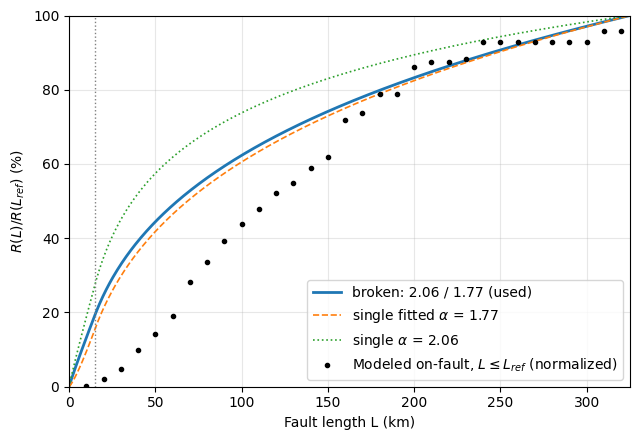

In [11]:
def R_c_model(L, a_short, a_long):
    """Conditional potency fraction R(L)/R(L_ref) of the broken power law; Lmax cancels."""
    return np.minimum(potency_cum(L, a_short, a_long) / potency_cum(L_REF_KM, a_short, a_long), 1.0)

def R_c(L):
    return R_c_model(L, ALPHA_SHORT, ALPHA)

# Modeled on-fault curve for the population L <= L_ref (San Andreas excluded)
pop = merged_lengths <= L_REF_KM + 1e-9
REF_EDGES_KM = np.arange(0.0, np.ceil(L_REF_KM / BIN_KM) * BIN_KM + BIN_KM / 2, BIN_KM)
FL_ref = REF_EDGES_KM[1:]                                         # bin upper edges 10..330 km
perbin_on_ref, _ = np.histogram(merged_lengths[pop], bins=REF_EDGES_KM, weights=merged_moments[pop])
Mo_on_cum_ref = np.cumsum(perbin_on_ref)
M_ON_REF = Mo_on_cum_ref[-1]                                      # on-fault moment of faults <= L_ref
assert np.isclose(M_ON_REF + M_SAF, Mtot_on)
R_bins = R_c(FL_ref)


print(f"On-fault moment in the polygon       : {Mtot_on:.3e} N·m/yr")
print(f"  faults <= L_ref (normalized)       : {M_ON_REF:.3e} N·m/yr ({M_ON_REF / Mtot_on:.1%})")
print(f"  San Andreas (excluded from target) : {M_SAF:.3e} N·m/yr ({M_SAF / Mtot_on:.1%})")
for L_ in (10, 15, 30, 60, 100):
    print(f"R_c({L_:3d} km): broken {R_c(L_):.3f}   single fitted {R_c_model(L_, ALPHA, ALPHA):.3f}   "
          f"single {ALPHA_SHORT:.2f} {R_c_model(L_, ALPHA_SHORT, ALPHA_SHORT):.3f}")

Lq = np.linspace(0.01, L_REF_KM, 500)
plt.figure(figsize=(6.5, 4.5))
for (a_s, a_l), ls, lab in [((ALPHA_SHORT, ALPHA), "-", rf"broken: {ALPHA_SHORT:.2f} / {ALPHA:.2f} (used)"),
                            ((ALPHA, ALPHA), "--", rf"single fitted $\alpha$ = {ALPHA:.2f}"),
                            ((ALPHA_SHORT, ALPHA_SHORT), ":", rf"single $\alpha$ = {ALPHA_SHORT:.2f}")]:
    plt.plot(Lq, 100 * R_c_model(Lq, a_s, a_l), ls, lw=2 if ls == "-" else 1.2, label=lab)
plt.plot(FL_ref, 100 * Mo_on_cum_ref / M_ON_REF, "k.", label=r"Modeled on-fault, $L \leq L_{ref}$ (normalized)")
plt.axvline(T_KM, color="gray", ls=":", lw=1)
plt.xlabel("Fault length L (km)"); plt.ylabel(r"$R(L)/R(L_{ref})$ (%)"); plt.ylim(0, 100); plt.xlim(0, L_REF_KM)
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.savefig(FIG_OUT / "cell20_length_distribution.png", dpi=300, bbox_inches="tight"); plt.show()

## 7. Missing faults per 10 km bin (0–100 km)

* **Theoretical count** in $[L_{lo}, L_{hi}]$: $N(\ge L_{lo}) - N(\ge L_{hi})$ from the broken power law (fitted $\alpha_l$ above $T$, anchored at $n_{tail}$ faults $\ge l_{min}$; $\alpha_s$ = 2.06 below $T$)
  ($L_{lo}$ = 5 km for the first bin). This extrapolates the fit below $l_{min}$.
* **Missing faults**: theoretical count − merged faults in the bin.

Above ~60 km the merged dataset already contains at least as many faults as the power law predicts
(missing ≤ 0), so there is nothing there to host extra moment. These bins are excluded from the allocation in section 8.

In [12]:
lo, hi = PANEL_EDGES_KM[:-1], PANEL_EDGES_KM[1:]
centers = 0.5 * (lo + hi)

theo_count = n_ge(np.maximum(lo, L_COUNT_FLOOR_KM)) - n_ge(hi)
merged_count = np.array([np.sum((merged_lengths > a) & (merged_lengths <= b)) for a, b in zip(lo, hi)], float)
missing_count = theo_count - merged_count
has_missing = missing_count > 0

# Counts use ALL merged traces (San Andreas included; it is > 100 km and does not enter these bins).
# Map "bin has missing faults" onto the fine (moment) bins of the L <= L_ref curve
eligible_fine = np.zeros(len(FL_ref), bool)
for a, b, ok in zip(lo, hi, has_missing):
    eligible_fine |= ok & (FL_ref > a) & (FL_ref <= b)
L_ELIG_MAX = hi[has_missing].max()

print(pd.DataFrame({"bin": [f"{a:.0f}-{b:.0f}" for a, b in zip(lo, hi)], "theoretical": theo_count,
                    "merged": merged_count, "missing": missing_count, "receives_moment": has_missing}
                   ).to_string(index=False, float_format="{:.1f}".format))
print(f"\nBins with missing faults: {lo[has_missing].min():.0f}-{L_ELIG_MAX:.0f} km")
for lab, (a_s, a_l) in [("single fitted alpha (final notebook)", (ALPHA, ALPHA)),
                        (f"single alpha = {ALPHA_SHORT:.2f}", (ALPHA_SHORT, ALPHA_SHORT))]:
    th_ = n_ge_model(np.maximum(lo, L_COUNT_FLOOR_KM), a_s, a_l) - n_ge_model(hi, a_s, a_l)
    ms_ = th_ - merged_count
    print(f"Reference, {lab}: missing total {ms_[ms_ > 0].sum():.0f}   (0-10: {ms_[0]:.0f}, 10-20: {ms_[1]:.0f})")
print(f"This notebook (broken): missing total {missing_count[has_missing].sum():.0f}")

   bin  theoretical  merged  missing  receives_moment
  0-10       6964.9    18.0   6946.9             True
 10-20       1686.5    51.0   1635.5             True
 20-30        340.8    41.0    299.8             True
 30-40        129.4    47.0     82.4             True
 40-50         63.5    23.0     40.5             True
 50-60         36.1    24.0     12.1             True
 60-70         22.7    26.0     -3.3            False
 70-80         15.2    17.0     -1.8            False
 80-90         10.7    11.0     -0.3            False
90-100          7.9    11.0     -3.1            False

Bins with missing faults: 0-60 km
Reference, single fitted alpha (final notebook): missing total 7470   (0-10: 5479, 10-20: 1557)
Reference, single alpha = 2.06: missing total 14858   (0-10: 11501, 10-20: 2711)
This notebook (broken): missing total 9017


## 8. Per-bin addition of the off-fault moment (conditional target, bins with missing faults only)

For a budget $M_{off}$:

1. Target cumulative curve: $\big(M_{on}(\le L_{ref}) + M_{off}\big)\,R(L)/R(L_{ref})$, broken power law.
2. Per-bin moment of target and model ($L \le L_{ref}$): `np.diff` of the cumulative curves.
3. Raw deficit per bin: $\max(\text{theory} - \text{model}, 0)$, kept **only in bins ≤ 100 km with missing faults**
   (section 7). No bin is ever reduced.
4. Rescale the raw deficits so they sum exactly to $M_{off}$.

The whole budget ends up on missing faults. A scale factor < 1 means the raw deficit of the eligible bins is larger
than the budget; > 1 would mean the budget exceeds it (flagged below).

In [13]:
def per_bin_additions(budget):
    theory_cum = (M_ON_REF + budget) * R_bins                    # conditional target (San Andreas excluded)
    raw_all = np.maximum(np.diff(np.r_[0.0, theory_cum]) - perbin_on_ref, 0.0)
    raw = np.where(eligible_fine & (FL_ref <= L_CUT_KM), raw_all, 0.0)
    if raw.sum() <= 0:
        raise RuntimeError("No positive deficit in bins with missing faults.")
    scale = budget / raw.sum()
    return raw * scale, scale, raw_all

add_perbin, add_scale = {}, {}
for case, budget in budgets.items():
    add_perbin[case], add_scale[case], raw_all = per_bin_additions(budget)
    excluded = raw_all[~eligible_fine & (FL_ref <= L_CUT_KM)].sum()
    print(f"{case:5s}: budget {budget:.3e}  scale {add_scale[case]:.3f}  sum added {add_perbin[case].sum():.3e}"
          f"  (raw deficit in ineligible bins <= {L_CUT_KM:.0f} km, redistributed: {excluded:.2e})")
    if add_scale[case] > 1:
        print(f"       NOTE: scale > 1, the {case} budget exceeds the positive deficit of the eligible bins")

theory_on_cum = M_ON_REF * R_bins
theory_onoff_cum = (M_ON_REF + budgets["best"]) * R_bins
adjusted_cum = {c: Mo_on_cum_ref + np.cumsum(add_perbin[c]) for c in budgets}

tbl = pd.DataFrame({
    "bin_upper_km": FL_ref,
    "eligible": eligible_fine,
    "model_on": perbin_on_ref,
    "theory_on+off": np.diff(np.r_[0.0, theory_onoff_cum]),
    "added_best": add_perbin["best"],
    "added_lower": add_perbin["lower"],
    "added_upper": add_perbin["upper"],
})
print(tbl[tbl.bin_upper_km <= L_CUT_KM].to_string(index=False, float_format="{:.3e}".format))

best : budget 9.004e+18  scale 1.138  sum added 9.004e+18  (raw deficit in ineligible bins <= 100 km, redistributed: 1.51e+17)
       NOTE: scale > 1, the best budget exceeds the positive deficit of the eligible bins
lower: budget 7.626e+18  scale 1.054  sum added 7.626e+18  (raw deficit in ineligible bins <= 100 km, redistributed: 6.32e+16)
       NOTE: scale > 1, the lower budget exceeds the positive deficit of the eligible bins
upper: budget 1.007e+19  scale 1.195  sum added 1.007e+19  (raw deficit in ineligible bins <= 100 km, redistributed: 2.46e+17)
       NOTE: scale > 1, the upper budget exceeds the positive deficit of the eligible bins
 bin_upper_km  eligible  model_on  theory_on+off  added_best  added_lower  added_upper
    1.000e+01      True 2.309e+16      2.736e+18   3.089e+18    2.668e+18    3.409e+18
    2.000e+01      True 2.283e+17      2.389e+18   2.459e+18    2.110e+18    2.727e+18
    3.000e+01      True 3.237e+17      1.707e+18   1.574e+18    1.338e+18    1.757e+18

## 9. Slip deficit rates and earthquake rates (10 km bins, 0–100 km)

* **Slip deficit rate**: $\dot s = \Delta \dot M_0 / (\mu\, N_{missing}\, L_{center}\, W)$, $W = T = 15$ km.
  Defined only for bins with missing faults, which are exactly the bins that receive moment.
* **Earthquakes per 100 yr**: $100\,\Delta\dot M_0 / M_0(M_w)$, with $M_w$ from the bin's upper-edge length
  (Wells & Coppersmith 1994) and $M_0$ from Hanks & Kanamori (1979), i.e. all moment released by the largest event of the bin.

In [14]:
Mw_bin = mw_from_length(hi)
M0_bin = m0_from_mw(Mw_bin)

def bin_table(add_fine):
    """Aggregate per-bin additions onto the panel bins and derive slip and earthquake rates."""
    added = np.array([add_fine[(FL_ref > a) & (FL_ref <= b)].sum() for a, b in zip(lo, hi)])
    area = missing_count * (centers * 1e3) * (T_KM * 1e3)          # m^2 of missing fault surface
    slip = np.full(len(added), np.nan)                             # undefined where no faults are missing
    slip[has_missing] = added[has_missing] / (mu * area[has_missing]) * 1e3   # mm/yr
    return pd.DataFrame({
        "bin_low_km": lo, "bin_high_km": hi, "bin_center_km": centers,
        "theoretical_count": theo_count, "merged_count": merged_count, "missing_count": missing_count,
        "added_moment_Nm_yr": added, "slip_rate_mm_yr": slip,
        "Mw": Mw_bin, "eq_per_100yr": 100.0 * added / M0_bin,
    })

bins_df = {c: bin_table(add_perbin[c]) for c in budgets}

for c, df in bins_df.items():
    assert not ((df.missing_count <= 0) & (df.added_moment_Nm_yr > 0)).any(), f"{c}: moment in a bin without missing faults"
    assert np.isclose(df.added_moment_Nm_yr.sum(), budgets[c]), f"{c}: added moment does not match the budget"
print(bins_df["best"].to_string(index=False, formatters={
    "theoretical_count": "{:.1f}".format, "merged_count": "{:.0f}".format, "missing_count": "{:.1f}".format,
    "added_moment_Nm_yr": "{:.3e}".format, "slip_rate_mm_yr": "{:.3f}".format,
    "Mw": "{:.2f}".format, "eq_per_100yr": "{:.3f}".format}))

 bin_low_km  bin_high_km  bin_center_km theoretical_count merged_count missing_count added_moment_Nm_yr slip_rate_mm_yr   Mw eq_per_100yr
          0           10            5.0            6964.9           18        6946.9          3.089e+18           0.198 6.15      146.826
         10           20           15.0            1686.5           51        1635.5          2.459e+18           0.223 6.56       28.686
         20           30           25.0             340.8           41         299.8          1.574e+18           0.467 6.79        8.072
         30           40           35.0             129.4           47          82.4          8.101e+17           0.624 6.96        2.318
         40           50           45.0              63.5           23          40.5          6.733e+17           0.820 7.09        1.226
         50           60           55.0              36.1           24          12.1          3.982e+17           1.324 7.20        0.501
         60           70          

### Gutenberg–Richter comparison (b = 1, $M_{w,max}$ = 7.5)

Alternative to the characteristic-event rates: the same added moment (best fit) distributed with a b = 1
Gutenberg–Richter law over the $M_w$ interval of each length bin, normalized so that the GR moment equals the added moment.
Table only (not plotted).

In [15]:
MW_MAX_GR = 7.5
MW_MIN_GR = 2.0   # lower Mw bound of the first (0-10 km) bin

M1 = np.clip(np.where(lo > 0, mw_from_length(np.maximum(lo, 1e-9)), MW_MIN_GR), MW_MIN_GR, MW_MAX_GR)
M2 = np.clip(mw_from_length(hi), MW_MIN_GR, MW_MAX_GR)
active = M2 > M1
A_N = np.where(active, (10 ** -M1 - 10 ** -M2) / np.log(10), 0.0)                              # ∫ 10^-M dM
A_M = np.where(active, 10 ** 9.1 * (10 ** (0.5 * M2) - 10 ** (0.5 * M1)) / (0.5 * np.log(10)), 0.0)  # ∫ 10^-M M0(M) dM
k_gr = add_perbin["best"].sum() / A_M.sum()

gr_df = pd.DataFrame({
    "bin_low_km": lo, "bin_high_km": hi, "Mw_low": M1, "Mw_high": M2,
    "GR_eq_per_100yr": 100 * k_gr * A_N,
    "characteristic_eq_per_100yr": bins_df["best"].eq_per_100yr,
})
print(gr_df.to_string(index=False, float_format="{:.3g}".format))
print(f"GR moment total {(k_gr * A_M).sum():.3e} = added moment {add_perbin['best'].sum():.3e}")

 bin_low_km  bin_high_km  Mw_low  Mw_high  GR_eq_per_100yr  characteristic_eq_per_100yr
          0           10       2     6.15         6.37e+05                          147
         10           20    6.15     6.56             27.5                         28.7
         20           30    6.56     6.79             7.48                         8.07
         30           40    6.79     6.96              3.3                         2.32
         40           50    6.96     7.09             1.81                         1.23
         50           60    7.09      7.2             1.12                        0.501
         60           70     7.2     7.29            0.756                            0
         70           80    7.29     7.37            0.539                            0
         80           90    7.37     7.44            0.401                            0
         90          100    7.44      7.5            0.308                            0
GR moment total 9.004e+18 = adde

## 10. Figure 3 in our manuscript

* **a** Cumulative moment rate of the faults up to $L_{ref}$ (San Andreas excluded): modeled, theory (on-fault and
  on+off, conditional normalization, broken power law) and on+off adjusted.
* **b** Missing faults per bin and slip deficit rate needed on them.
* **c** Missing moment rate per bin.
* **d** Characteristic earthquakes per 100 years from the missing moment rate.

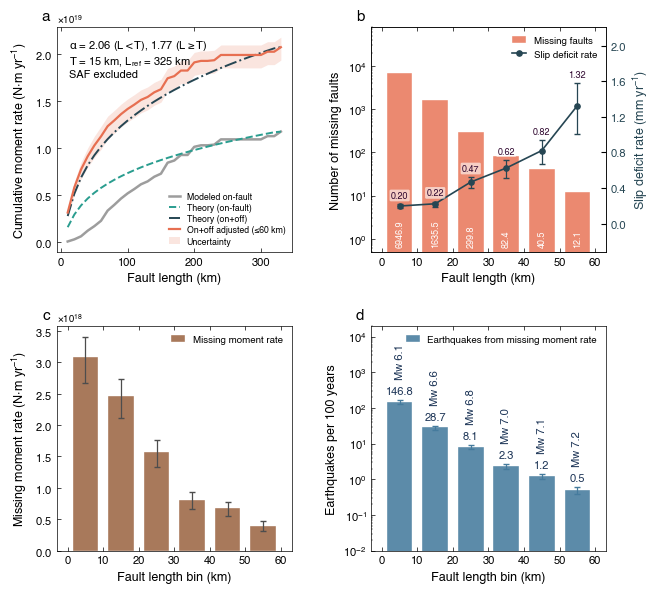

In [16]:
best, lower, upper = bins_df["best"], bins_df["lower"], bins_df["upper"]

def err_bars(y, y_lo, y_hi):
    """Asymmetric error bars; NaN bounds give zero-length bars."""
    return [np.nan_to_num(np.maximum(y - y_lo, 0)), np.nan_to_num(np.maximum(y_hi - y, 0))]

c_model, c_on, c_onoff, c_nf, c_add, c_eq = "#4d4d4d", "#2a9d8f", "#264653", "#e76f51", "#9c6644", "#457b9d"

with plt.rc_context({
    "font.family": "sans-serif", "font.sans-serif": ["Helvetica", "Arial", "DejaVu Sans"],
    "font.size": 8, "axes.labelsize": 9, "axes.linewidth": 0.5,
    "xtick.direction": "in", "ytick.direction": "in", "xtick.top": True,
    "legend.frameon": False, "legend.fontsize": 7, "legend.handlelength": 1.4,
    "mathtext.default": "regular",
}):
    fig = plt.figure(figsize=(7.08, 6.8))
    gs = gridspec.GridSpec(2, 2, hspace=0.33, wspace=0.34)
    bw = 0.72 * np.median(np.diff(centers))

    # ----- a: cumulative moment rates -----
    ax_a = fig.add_subplot(gs[0, 0])
    ax_a.plot(FL_ref, Mo_on_cum_ref, lw=1.8, color=c_model, alpha=0.55, label="Modeled on-fault")
    ax_a.plot(FL_ref, theory_on_cum, lw=1.4, ls="--", color=c_on, label="Theory (on-fault)")
    ax_a.plot(FL_ref, theory_onoff_cum, lw=1.4, ls="-.", color=c_onoff, label="Theory (on+off)")
    ax_a.plot(FL_ref, adjusted_cum["best"], lw=1.6, color=c_nf, label=f"On+off adjusted (≤{L_ELIG_MAX:.0f} km)")
    ax_a.fill_between(FL_ref, adjusted_cum["lower"], adjusted_cum["upper"], color=c_nf, alpha=0.18,
                      lw=0, zorder=0, label="Uncertainty")
    ax_a.set_xlabel("Fault length (km)")
    ax_a.set_ylabel(r"Cumulative moment rate (N$\cdot$m yr$^{-1}$)")
    ax_a.legend(loc="lower right", fontsize=6.3, labelspacing=0.25, borderaxespad=0.3, handlelength=1.2)
    ax_a.text(0.05, 0.95, rf"$\alpha$ = {ALPHA_SHORT:.2f} ($L<T$), {ALPHA:.2f} ($L \geq T$)" + "\n"
              + rf"$T$ = {T_KM:.0f} km, $L_{{ref}}$ = {L_REF_KM:.0f} km" + "\n"
              + f"SAF excluded",
    #          + f"SAF excluded ({M_SAF / Mtot_on:.0%} of on-fault)",
              transform=ax_a.transAxes, va="top", fontstyle="italic")
    ax_a.set_ylim(top=1.05 * np.nanmax(adjusted_cum["upper"]))   # room for the label above the curves

    # ----- b: missing faults + slip deficit rate -----
    ax_b = fig.add_subplot(gs[0, 1])
    x, nmiss = best.bin_center_km.values, best.missing_count.values
    ax_b.bar(x, np.where(nmiss > 0, nmiss, np.nan), width=bw, color=c_nf, alpha=0.82,
             edgecolor="white", linewidth=0.35, label="Missing faults")
    for xi, yi in zip(x, nmiss):
        if yi > 0:
            ax_b.text(xi, 0.65, f"{yi:.1f}", ha="center", va="bottom", fontsize=6.5, color="white", rotation=90)
    ax_b.set_yscale("log"); ax_b.set_ylim(0.5, 8e4)
    ax_b.set_xlabel("Fault length (km)"); ax_b.set_ylabel("Number of missing faults")

    ax_b2 = ax_b.twinx()
    s, s_lo, s_hi = best.slip_rate_mm_yr.values, lower.slip_rate_mm_yr.values, upper.slip_rate_mm_yr.values
    ax_b2.plot(x, s, color=c_onoff, lw=1.2, marker="o", ms=3.8, label="Slip deficit rate")
    ax_b2.errorbar(x, s, yerr=err_bars(s, s_lo, s_hi), fmt="none", ecolor=c_onoff, elinewidth=0.9, capsize=2.5)
    s_top = np.nanmax(s_hi)
    added_best = best.added_moment_Nm_yr.values
    for xi, si, shi, ai in zip(x, s, s_hi, added_best):
        if np.isfinite(si):
            ax_b2.text(xi, np.nanmax([si, shi]) + 0.03 * s_top, f"{si:.2f}", ha="center", va="bottom", fontsize=6.5,
                       color="#2F072F", bbox=dict(boxstyle="round,pad=0.15", facecolor="white", edgecolor="none", alpha=0.6))
        elif ai > 0:
            ax_b2.text(xi, 0.02 * s_top, "n/a", ha="center", va="bottom", fontsize=6.5, color=c_model)
    ax_b2.set_ylim(-0.2 * s_top, 1.4 * s_top)   # lift slip zero above the count labels at the bar bases
    #ax_b2.set_ylim(-0.45 * s_top, 1.2 * s_top)   # lift slip zero above the count labels at the bar bases
    ax_b2.yaxis.set_major_locator(mticker.FixedLocator([t for t in mticker.MaxNLocator(5).tick_values(0, 1.2 * s_top) if t >= 0]))
    ax_b.set_xlim(PANEL_EDGES_KM[0] - 3, PANEL_EDGES_KM[-1] + 3)   # keep 0-100 km even where values are NaN
    ax_b2.set_ylabel(r"Slip deficit rate (mm yr$^{-1}$)", color=c_onoff)
    ax_b2.tick_params(axis="y", labelcolor=c_onoff)
    h1, l1 = ax_b.get_legend_handles_labels(); h2, l2 = ax_b2.get_legend_handles_labels()
    ax_b.legend(h1 + h2, l1 + l2, loc="upper right")
    ax_b.set_xlim(lo[has_missing].min() - 3, hi[has_missing].max() + 3) 

    # ----- c: missing moment rate -----
    ax_c = fig.add_subplot(gs[1, 0])
    y, y_lo, y_hi = best.added_moment_Nm_yr.values, lower.added_moment_Nm_yr.values, upper.added_moment_Nm_yr.values
    ax_c.bar(x, y, width=bw, color=c_add, alpha=0.88, edgecolor="white", linewidth=0.3, label="Missing moment rate")
    ax_c.errorbar(x, y, yerr=err_bars(y, y_lo, y_hi), fmt="none", ecolor=c_model, elinewidth=0.9, capsize=2.5)
    ax_c.set_xlabel("Fault length bin (km)"); ax_c.set_ylabel(r"Missing moment rate (N$\cdot$m yr$^{-1}$)")
    ax_c.legend(loc="upper right")
    ax_c.set_xlim(lo[has_missing].min() - 3, hi[has_missing].max() + 3) 

    # ----- d: earthquakes per 100 years -----
    ax_d = fig.add_subplot(gs[1, 1])
    q, q_lo, q_hi = best.eq_per_100yr.values, lower.eq_per_100yr.values, upper.eq_per_100yr.values
    ax_d.bar(x, np.where(q > 0, q, np.nan), width=bw, color=c_eq, alpha=0.88, edgecolor="white", linewidth=0.3,
             label="Earthquakes from missing moment rate")
    ax_d.errorbar(x, q, yerr=err_bars(q, q_lo, q_hi), fmt="none", ecolor=c_eq, elinewidth=0.9, capsize=2.5)
    for xi, qi, qu, mw in zip(x, q, q_hi, best.Mw.values):
        if qi > 0:
            y0 = max(qi, qu) * 1.3                  # start above the upper error bar
            ax_d.text(xi, y0, f"{qi:.1f}", ha="center", va="bottom", fontsize=8, color="#1d3557")
            ax_d.text(xi, y0 * 3.0, f"Mw {mw:.1f}", ha="center", va="bottom", fontsize=8, color="#1d3557", rotation=90)
        elif qu > 0:
            ax_d.text(xi, qu * 1.5, f"Mw {mw:.1f}", ha="center", va="bottom", fontsize=8, color="#1d3557", rotation=90)
    ax_d.set_yscale("log"); ax_d.set_ylim(1e-2, 2e4)
    for ax in (ax_c, ax_d):
        ax.set_xlim(lo[has_missing].min() - 3, hi[has_missing].max() + 3) 
    ax_d.set_xlabel("Fault length bin (km)"); ax_d.set_ylabel("Earthquakes per 100 years")
    ax_d.legend(loc="upper right")

    for ax, lab in zip([ax_a, ax_b, ax_c, ax_d], "abcd"):
        ax.text(-0.03, 1.08, lab, transform=ax.transAxes, fontsize=11, fontweight="bold", va="top", ha="right")
        ax.tick_params(which="major", length=3, width=0.5)
        ax.tick_params(which="minor", length=1.5, width=0.3)
        ax.yaxis.get_offset_text().set_fontsize(7)
    for ax in (ax_a, ax_c):
        ax.yaxis.set_major_formatter(mticker.ScalarFormatter(useMathText=True))
        ax.ticklabel_format(axis="y", style="sci", scilimits=(-2, 2))

    plt.savefig(f"{OUT_PREFIX}_4panel.pdf", dpi=300, bbox_inches="tight")
    plt.savefig(f"{OUT_PREFIX}_4panel.png", dpi=300, bbox_inches="tight")
    plt.show()

## 11. Summary table (best fit with lower and upper bounds) and CSV

In [17]:
summary = best[["bin_low_km", "bin_high_km", "theoretical_count", "merged_count", "missing_count", "Mw"]].copy()
for c in ("lower", "best", "upper"):
    summary[f"added_{c}"] = bins_df[c].added_moment_Nm_yr
    summary[f"slip_{c}_mm_yr"] = bins_df[c].slip_rate_mm_yr
    summary[f"eq100_{c}"] = bins_df[c].eq_per_100yr
summary.to_csv(f"{OUT_PREFIX}_section10_bins.csv", index=False)
print(f"Broken power law: alpha_s = {ALPHA_SHORT:.2f} (L < {L_BREAK_KM:.0f} km), "
      f"alpha_l = {ALPHA:.3f} [{ALPHA_CI[0]:.3f}, {ALPHA_CI[1]:.3f}], lmin = {LMIN:.2f} km, N_TAIL = {N_TAIL}, "
      f"L_ref = {L_REF_KM:.1f} km, T = W = {T_KM:.0f} km")
print(f"On-fault moment in polygon {Mtot_on:.3e}, normalized (L <= L_ref) {M_ON_REF:.3e}, "
      f"San Andreas excluded {M_SAF:.3e} N·m/yr")
print("Scale factors: " + ", ".join(f"{c} {add_scale[c]:.3f}" for c in budgets))
print(summary.to_string(index=False, float_format="{:.3g}".format))
print(f"\nWritten: {OUT_PREFIX}_4panel.pdf/.png, {OUT_PREFIX}_section10_bins.csv")

Broken power law: alpha_s = 2.06 (L < 15 km), alpha_l = 1.774 [1.543, 2.083], lmin = 51.54 km, N_TAIL = 124, L_ref = 325.2 km, T = W = 15 km
On-fault moment in polygon 1.733e+19, normalized (L <= L_ref) 1.174e+19, San Andreas excluded 5.585e+18 N·m/yr
Scale factors: best 1.138, lower 1.054, upper 1.195
 bin_low_km  bin_high_km  theoretical_count  merged_count  missing_count   Mw  added_lower  slip_lower_mm_yr  eq100_lower  added_best  slip_best_mm_yr  eq100_best  added_upper  slip_upper_mm_yr  eq100_upper
          0           10           6.96e+03            18       6.95e+03 6.15     2.67e+18             0.171          127    3.09e+18            0.198         147     3.41e+18             0.218          162
         10           20           1.69e+03            51       1.64e+03 6.56     2.11e+18             0.191         24.6    2.46e+18            0.223        28.7     2.73e+18             0.247         31.8
         20           30                341            41            300 6.

## 11b. Comparison with possible variants and modelling choices

Same pipeline (counts → eligible bins → conditional target → rescaled additions → slip and earthquake rates), rerun with
four choices of the exponents used for the **counts** and for **$R(L)$**:

| Variant | Counts | $R(L)$ | 
|---|---|---|
| A | single fitted α | single fitted α | 
| B | single fitted α | single 2.06 | 
| C | single 2.06 | single 2.06 | 
| D | broken (2.06 / fitted) | broken (2.06 / fitted) | 

Earthquake rates depend only on the added moment (through $R$ and the eligible bins); slip rates also depend on the
number of missing faults.


missing (best budget), bins 0-60 km
       A fitted/fitted  B fitted/2.06  C 2.06/2.06  D broken/broken
0-10              5479           5479        11501             6947
10-20             1557           1557         2711             1636
20-30              300            300          452              300
30-40               82             82          122               82
40-50               41             41           54               41
50-60               12             12           17               12

slip_mm_yr (best budget), bins 0-60 km
       A fitted/fitted  B fitted/2.06  C 2.06/2.06  D broken/broken
0-10              0.19           0.27         0.13             0.20
10-20             0.25           0.25         0.14             0.22
20-30             0.53           0.45         0.30             0.47
30-40             0.72           0.57         0.38             0.62
40-50             0.95           0.66         0.49             0.82
50-60             1.59           0.94  

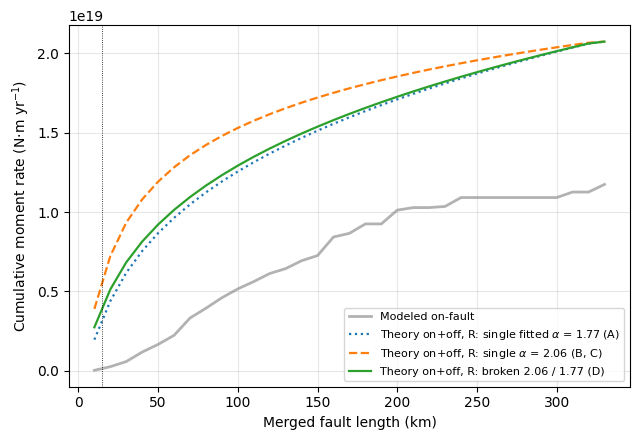

In [18]:
def run_variant(count_exps, R_exps, budget):
    """Rerun sections 7-9 for given (a_short, a_long) of the counts and of R(L). Returns the panel-bin table."""
    th = n_ge_model(np.maximum(lo, L_COUNT_FLOOR_KM), *count_exps) - n_ge_model(hi, *count_exps)
    miss = th - merged_count
    hm = miss > 0
    elig = np.zeros(len(FL_ref), bool)
    for a, b, ok in zip(lo, hi, hm):
        elig |= ok & (FL_ref > a) & (FL_ref <= b)
    target = (M_ON_REF + budget) * R_c_model(FL_ref, *R_exps)
    raw = np.maximum(np.diff(np.r_[0.0, target]) - perbin_on_ref, 0.0)
    raw = np.where(elig & (FL_ref <= L_CUT_KM), raw, 0.0)
    add = raw * budget / raw.sum()
    added = np.array([add[(FL_ref > a) & (FL_ref <= b)].sum() for a, b in zip(lo, hi)])
    slip = np.full(len(lo), np.nan)
    slip[hm] = added[hm] / (mu * miss[hm] * centers[hm] * 1e3 * T_KM * 1e3) * 1e3
    return pd.DataFrame({"missing": miss, "added": added, "slip_mm_yr": slip, "eq_per_100yr": 100 * added / M0_bin}), \
           budget / np.where(elig & (FL_ref <= L_CUT_KM), np.maximum(np.diff(np.r_[0.0, target]) - perbin_on_ref, 0), 0).sum()

variants = {
    "A fitted/fitted": ((ALPHA, ALPHA), (ALPHA, ALPHA)),
    "B fitted/2.06":   ((ALPHA, ALPHA), (ALPHA_SHORT, ALPHA_SHORT)),
    "C 2.06/2.06":     ((ALPHA_SHORT, ALPHA_SHORT), (ALPHA_SHORT, ALPHA_SHORT)),
    "D broken/broken": ((ALPHA_SHORT, ALPHA), (ALPHA_SHORT, ALPHA)),
}
var_out = {k: run_variant(c, r, budgets["best"]) for k, (c, r) in variants.items()}

# Variant D must reproduce the main pipeline of this notebook
assert np.allclose(var_out["D broken/broken"][0].added, bins_df["best"].added_moment_Nm_yr)
assert np.allclose(var_out["D broken/broken"][0].missing, bins_df["best"].missing_count)

bin_lab = [f"{a:.0f}-{b:.0f}" for a, b in zip(lo, hi)]
for col, fmt in [("missing", "{:.0f}"), ("slip_mm_yr", "{:.2f}"), ("eq_per_100yr", "{:.2f}")]:
    t = pd.DataFrame({k: v[0][col].values for k, v in var_out.items()}, index=bin_lab)
    t = t[(t.index.map(lambda s: float(s.split("-")[0])) < 60)]
    print(f"\n{col} (best budget), bins 0-60 km")
    print(t.to_string(float_format=fmt.format))
print("\nScale factors (budget / raw eligible deficit): "
      + ", ".join(f"{k} {v[1]:.2f}" for k, v in var_out.items()))
print("Total missing faults: " + ", ".join(f"{k} {v[0].missing[v[0].missing > 0].sum():.0f}" for k, v in var_out.items()))

# Theory (on+off) curves for the three distinct R(L) choices (B and C share R with alpha = 2.06)
plt.figure(figsize=(6.5, 4.5))
plt.plot(FL_ref, Mo_on_cum_ref, color="gray", lw=2, alpha=0.6, label="Modeled on-fault")
for R_exps, ls, lab in [((ALPHA, ALPHA), ":", rf"R: single fitted $\alpha$ = {ALPHA:.2f} (A)"),
                        ((ALPHA_SHORT, ALPHA_SHORT), "--", rf"R: single $\alpha$ = {ALPHA_SHORT:.2f} (B, C)"),
                        ((ALPHA_SHORT, ALPHA), "-", f"R: broken {ALPHA_SHORT:.2f} / {ALPHA:.2f} (D)")]:
    plt.plot(FL_ref, (M_ON_REF + budgets["best"]) * R_c_model(FL_ref, *R_exps), ls, lw=1.6, label="Theory on+off, " + lab)
plt.axvline(T_KM, color="k", lw=0.6, ls=":")
plt.xlabel("Merged fault length (km)"); plt.ylabel(r"Cumulative moment rate (N$\cdot$m yr$^{-1}$)")
plt.legend(fontsize=8); plt.grid(alpha=0.3); plt.tight_layout(); plt.savefig(FIG_OUT / "cell34_length_distribution.png", dpi=300, bbox_inches="tight"); plt.show()

## 12. Notes 

**What our approach assumes.**

1. **The San Andreas is treated as a separate mature fault**: it stays in the length statistics (its counts are expected
   from the fit) but its moment is outside the normalization. We normalize
   $M_{on}(\le L_{ref}) + M_{off}$, not the full on-fault total (which includes the moment from the San Andreas fault).
2. **Two exponents, one population.** α_l is fitted above $l_{min}$ ≈ 51 km and extrapolated down to $T$; α_s = 2.06
   below $T$ is taken from Z&F (2024), not measured here (the catalog is incomplete below $l_{min}$). The break location
   ($T$) is physically motivated but not demonstrated: Z&F note that their data sets spanning $T$ show no obvious break.
   The counts and $R(L)$ use the same distribution, so the missing faults and the moment they host are consistent.
   Section 11b shows how much the results depend on this choice.

**Robustness.** In our sensitivity tests (11b), the 0–30 km slip deficit rates change little
between methods; the 40–60 km bins are method-dependent. However, the main conclusions of our study remain robust: Thousands of faults slipping at geologicaly significant rates are required to accommodate the geodetically derived off-fault moment rate